<p align="center">
  <img src="assets/hero_kavram.svg" width="100%" alt="Gün 52 — LightGBM: Yaprak yaprak büyüyen akıllı ekip">
</p>

<p align="center">
  <img src="https://img.shields.io/badge/G%C3%BCn-52-0B3A52?style=for-the-badge" alt="Gün 52">
  <img src="https://img.shields.io/badge/Konu-LightGBM_(Kavram)-E5A100?style=for-the-badge" alt="Konu">
  <img src="https://img.shields.io/badge/Seviye-Ba%C5%9Flang%C4%B1%C3%A7-16A34A?style=for-the-badge" alt="Seviye">
  <img src="https://img.shields.io/badge/Veri-Titanik-0EA5C6?style=for-the-badge" alt="Veri">
  <img src="https://img.shields.io/badge/Animasyon-5_GIF-D1495B?style=for-the-badge" alt="Animasyon">
</p>

<table>
<tr><td width="25%" valign="top" align="center"><h3>🪣</h3><b>Kova hilesi</b><br><br>Sayıları <b>kovalara</b> atıp<br>bölünmeyi kovalar arasında ara<br><br></td><td width="25%" valign="top" align="center"><h3>🍃</h3><b>Yaprak yaprak</b><br><br>Ağacı katman katman değil,<br><b>en çok kazandıran yaprağı</b> büyüterek kur<br><br></td><td width="25%" valign="top" align="center"><h3>🏷️</h3><b>Kategori dostu</b><br><br>Liman, unvan, güverte gibi<br>etiketleri <b>sayıya çevirmeden</b> anla<br><br></td><td width="25%" valign="top" align="center"><h3>⚖️</h3><b>Kazanç hesabı</b><br><br>Bir bölünmenin<br><b>ne kadar işe yaradığını</b> ölç<br><br></td></tr>
</table>

<table><tr><td>

<img src="assets/etiket_hedef.svg" height="34" alt="Hedefler">

**Bu notebook'un sonunda şunları yapabiliyor olacaksınız:**

- 🚢 LightGBM'in **"hatadan öğrenen ekip"** fikrini 8 Titanik yolcusu üzerinde, **elle hesaplayarak** anlatmak
- 🧮 Elle bulduğunuz sayıları **gerçek `lightgbm`** ile doğrulamak
- 🪣 **Kova (histogram)** hilesinin neden hız kazandırdığını görmek
- 🍃 **Yaprak yaprak** ile **katman katman** büyümenin farkını animasyonla izlemek
- 🏷️ Kategorik sütunların LightGBM'de **doğrudan** kullanılabildiğini ölçmek
- ⚖️ **Kazanç (gain)** kavramını anlamak ve XGBoost'la **adil bir yarış** koşmak
- 🛡️ Küçük veride **ezberi önleyen düğmeleri** tanımak

Teknik ayrıntı bilinçli olarak az tutuldu; her kavramın yanında **bir resim, bir animasyon ve bir deney** var.

</td></tr></table>

<p align="center">
  <img src="assets/yol_haritasi_kavram.svg" width="100%" alt="Kavram yol haritası: 11 durak">
</p>

### 🧭 Hızlı Erişim

| Durak | Bölüm | Ana soru |
|:-:|:--|:--|
| 🧰 1 | [Kurulum](#p1) | Hangi araçlarla çalışıyoruz? |
| 💡 2 | [Büyük fikir](#p2) | Boosting nedir, LightGBM neyi farklı yapar? |
| 🔁 3 | [Beş adımlık döngü](#p3) | Model nasıl öğrenir? (8 yolcuyla elle hesap) |
| 🪣 4 | [Kova hilesi](#p4) | Sayıları kovalamak neden hızlandırır? |
| 🍃 5 | [Yaprak yaprak büyüme](#p5) | Katman katman mı, yaprak yaprak mı? |
| 🏷️ 6 | [Kategorik sütunlar](#p6) | Etiketler sayıya çevrilmeli mi? |
| ⚖️ 7 | [Kazanç (gain)](#p7) | Bir bölünme ne kadar işe yaradı? |
| 🏁 8 | [XGBoost ile yarış](#p8) | İki kardeşten hangisi daha hızlı, daha iyi? |
| 🛡️ 9 | [Frenler ve düğmeler](#p9) | Küçük veride ezberi ne önler? |
| 🎞️ 10 | [Canlı model](#p10) | Model tur tur nasıl şekillenir? |
| 🎓 11 | [Özet](#p11) | Akılda kalanlar, quiz, ödevler, kaynakça |

<a id="p1"></a>

<p align="center">
  <img src="assets/kavram_01.svg" width="100%" alt="Bölüm 1">
</p>

Kütüphaneleri ve çizim yardımcılarını tek hücrede topluyoruz. Animasyonlar `outputs/figures` klasörüne **GIF** olarak kaydedilir ve notebook içinde oynatılır.

In [1]:
# ── Kütüphaneler ─────────────────────────────────────────────
import os, time, warnings, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import xgboost
import sklearn
from IPython.display import Image, Markdown, display
from matplotlib.animation import FuncAnimation, PillowWriter
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_val_score, StratifiedKFold
from sklearn.metrics import accuracy_score, log_loss, roc_auc_score, f1_score
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

from titanik_yardimci import veri_oku, OzellikUretici, SAYISAL, KATEGORIK

warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"
RANDOM_STATE = 42
FIG_DIR = Path("outputs/figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)
REP_DIR = Path("outputs/reports"); REP_DIR.mkdir(parents=True, exist_ok=True)

# Renk paleti (Titanik teması: okyanus + altın)
RENK = {"altin": "#E5A100", "mavi": "#2B6CB0", "cyan": "#0E9AA7", "yesil": "#2E9E6B", "pembe": "#D1495B",
        "mor": "#6C5CE7", "turuncu": "#E8833A", "gri": "#8A94A6", "koyu": "#1F2A44"}
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight", "axes.titleweight": "bold",
                     "axes.titlesize": 13, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False, "grid.alpha": 0.25})


def kaydet(fig, ad):
    """Grafiği outputs/figures altına PNG olarak kaydeder."""
    fig.savefig(FIG_DIR / f"{ad}.png")
    print(f"💾 Kaydedildi → outputs/figures/{ad}.png")


def gif_kaydet(kare_ciz, n_kare, ad, figsize=(8, 4.4), fps=6):
    """kare_ciz(i, ax_listesi) fonksiyonuyla animasyon üretir, GIF olarak kaydeder ve gösterir."""
    fig = plt.figure(figsize=figsize)
    def guncelle(i):
        fig.clear(); kare_ciz(i, fig)
        try: fig.tight_layout()
        except Exception: pass
        return []
    anim = FuncAnimation(fig, guncelle, frames=n_kare, blit=False)
    yol = FIG_DIR / f"{ad}.gif"
    anim.save(yol, writer=PillowWriter(fps=fps), dpi=80)
    plt.close(fig)
    print(f"🎞️ Animasyon → {yol}")
    display(Image(filename=str(yol)))


def rapor_kaydet(df, ad, index=True):
    """Tabloyu outputs/reports altına CSV olarak yazar."""
    df.to_csv(REP_DIR / f"{ad}.csv", index=index, encoding="utf-8-sig")
    print(f"📄 Rapor → outputs/reports/{ad}.csv")

print("lightgbm", lgb.__version__, "| xgboost", xgboost.__version__, "| scikit-learn", sklearn.__version__)

lightgbm 4.7.0 | xgboost 3.4.1 | scikit-learn 1.9.1


<a id="p2"></a>

<p align="center">
  <img src="assets/kavram_02.svg" width="100%" alt="Bölüm 2">
</p>

### 💡 2.1 · Hata Yapan Ama Öğrenen Ekip

Tek bir karar ağacı, **tek bir uzman** gibidir: bir şeyler öğrenir ama gürültüye de kapılır. **Boosting** farklı çalışır: önce **küçük bir çırak** (basit bir ağaç) tahmin yapar. Sonraki çırak yalnızca **öncekinin hatalarına** bakar ve onları düzeltmeye çalışır. Üçüncü çırak kalan hatalara bakar… Yüzlerce küçük çırak, **birbirinin eksiğini kapatarak** güçlü bir ekip olur.

LightGBM (Ke vd., 2017) bu fikri değiştirmez; yalnızca **çok daha hızlı ve hafif** çalıştırır. Bu notebook'ta Titanik yolcularının **hayatta kalıp kalmadığını** tahmin ederek öğreneceğiz.

<p align="center">
  <img src="assets/diyagram_aile.svg" width="100%" alt="Boosting ailesi">
</p>

Fikir, **gradyan artırma** (Friedman, 2001) ile başladı; **XGBoost** (Chen ve Guestrin, 2016) düzenleme ve sistem mühendisliği ekledi; **LightGBM** (Ke vd., 2017) kova, yaprak yaprak büyüme gibi hilelerle hızı artırdı; **CatBoost** (Prokhorenkova vd., 2018) kategorik sütunlarla öne çıktı. **Aynı temel döngü**, farklı mühendislik.

In [2]:
ham = veri_oku()
print("Satır, sütun:", ham.shape)
display(ham.head(4))
print("\nHayatta kalma oranı:", round(ham["Survived"].mean(), 3))
print("Eksik değerler:\n", ham.isna().sum()[ham.isna().sum() > 0].to_string())

Satır, sütun: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S



Hayatta kalma oranı: 0.384
Eksik değerler:
 Age         177
Cabin       687
Embarked      2


<table><tr><td>

<img src="assets/etiket_ipucu.svg" height="34" alt="İpucu">

**Veri hakkında:** 891 yolcu, hedef `Survived` (1 = kurtuldu). `Age` (yaş), `Cabin` (kabin) ve `Embarked` (biniş limanı) eksik değerler içerir. LightGBM eksik değerleri **kendisi** yönetebilir; bu yüzden bu derste boşlukları doldurmaya gerek yok.

</td></tr></table>

Şimdi ilk deney: **tek bir derin ağaç** mı, yoksa **küçük ağaçlardan oluşan bir ekip** mi daha iyi öğreniyor? Aynı veriyi hazırlayıp 5 katlı çapraz doğrulama ile deneyelim.

,0,1,2
Pclass,3.0,1.0,3.0
Age,22.0,38.0,26.0
SibSp,1.0,1.0,0.0
Parch,0.0,0.0,0.0
Fare,7.25,71.2833,7.925
AileBoyu,2.0,2.0,1.0
YalnizMi,0.0,0.0,1.0
BiletGrubu,1.0,1.0,1.0
KisiBasiUcret,7.25,71.2833,7.925
YasEksik,0.0,0.0,0.0


Tek derin ağaç     doğruluk = 0.803 ± 0.021
150 küçük çırak    doğruluk = 0.831 ± 0.021
💾 Kaydedildi → outputs/figures/kavram_01_tek_mi_ekip_mi.png


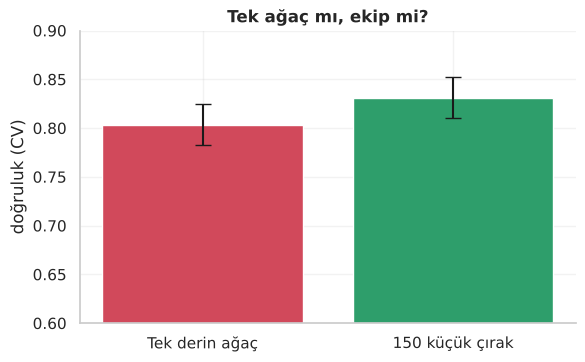

In [3]:
X = OzellikUretici().fit_transform(ham)          # 15 özellik: yaş, ücret, unvan, aile boyu, güverte...
y = ham["Survived"].to_numpy()
for c in KATEGORIK:
    X[c] = X[c].astype("category")              # LightGBM kategori sütunlarını doğrudan okur
display(X.head(3).T)

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

def cv_skor(model, X, y):
    """3×5 katlı doğrulamada ortalama doğruluk ve standart sapma."""
    s = cross_val_score(model, X, y, cv=cv, scoring="accuracy", n_jobs=1)
    return s.mean(), s.std()

tek = LGBMClassifier(n_estimators=1, learning_rate=1.0, num_leaves=64, min_child_samples=2, verbosity=-1, random_state=RANDOM_STATE)
ekip = LGBMClassifier(n_estimators=150, learning_rate=0.05, num_leaves=8, min_child_samples=10, verbosity=-1, random_state=RANDOM_STATE)
sonuc = {"Tek derin ağaç": cv_skor(tek, X, y), "150 küçük çırak": cv_skor(ekip, X, y)}
for ad, (m, s) in sonuc.items(): print(f"{ad:<18s} doğruluk = {m:.3f} ± {s:.3f}")

fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.bar(list(sonuc), [v[0] for v in sonuc.values()], yerr=[v[1] for v in sonuc.values()], color=[RENK["pembe"], RENK["yesil"]], capsize=6)
ax.set_ylim(0.6, 0.9); ax.set(title="Tek ağaç mı, ekip mi?", ylabel="doğruluk (CV)")
kaydet(fig, "kavram_01_tek_mi_ekip_mi"); plt.show()

<a id="p3"></a>

<p align="center">
  <img src="assets/kavram_03.svg" width="100%" alt="Bölüm 3">
</p>

LightGBM'in tüm öğrenme süreci **beş adımın tekrarıdır**:

<p align="center">
  <img src="assets/diyagram_dongu.svg" width="100%" alt="Beş adımlık döngü">
</p>

Örneğimiz **8 Titanik yolcusu**: cinsiyet, sınıf, yaş ve kurtulup kurtulmadıkları. Soru: *kim kurtuldu?*

In [4]:
yolcu = pd.DataFrame({
    "Yolcu": list("ABCDEFGH"),
    "Kadın (1/0)": [1, 1, 0, 0, 1, 0, 0, 1],
    "Sınıf": [1, 3, 1, 3, 3, 2, 3, 2],
    "Yaş": [29, 22, 48, 25, 18, 8, 35, 40],
    "Kurtuldu (1/0)": [1, 1, 0, 0, 0, 1, 0, 1],
})
Xo = yolcu[["Kadın (1/0)", "Sınıf", "Yaş"]].rename(columns={"Kadın (1/0)": "Kadin", "Sınıf": "Sinif", "Yaş": "Yas"})
yo = yolcu["Kurtuldu (1/0)"].to_numpy()
display(yolcu.set_index("Yolcu").T)
print("Kurtulan sayısı:", yo.sum(), "/", len(yo))

Yolcu,A,B,C,D,E,F,G,H
Kadın (1/0),1,1,0,0,1,0,0,1
Sınıf,1,3,1,3,3,2,3,2
Yaş,29,22,48,25,18,8,35,40
Kurtuldu (1/0),1,1,0,0,0,1,0,1


Kurtulan sayısı: 4 / 8


<table><tr><td>

<img src="assets/etiket_ipucu.svg" height="34" alt="İpucu">

**Dikkat:** E yolcusu (kadın, 3. sınıf) kurtulamadı; F (8 yaşında bir çocuk) ise kurtuldu. Gerçek veride de her zaman böyle **sürprizler** olur.

</td></tr></table>

### 🎲 3.1 · İlk Tahmin: "Ortalamayı Söyle"

Hiçbir şey bilmiyorsak en mantıklı cevap **ortalamadır**: 8 yolcudan 4'ü kurtuldu → herkese "%50". LightGBM olasılığı doğrudan değil, toplaması kolay bir ölçekte (**log-odds**) tutar: `log-odds = ln(p / (1−p))`. %50 → log-odds **0**. Geri dönüş **sigmoid** iledir: `p = 1 / (1 + e^(−log-odds))`.

In [5]:
def sigmoid(z): return 1 / (1 + np.exp(-z))
p0 = yo.mean(); lo0 = np.log(p0 / (1 - p0))
print(f"Başlangıç olasılığı p₀ = {p0:.2f} → log-odds = {lo0:.2f} → sigmoid geri dönüşü = {sigmoid(lo0):.2f}")

Başlangıç olasılığı p₀ = 0.50 → log-odds = 0.00 → sigmoid geri dönüşü = 0.50


### ❌ 3.2 · Artık: Her Yolcu Ne Kadar Yanlış?

**Artık = gerçek − tahmin.** Kurtulan için `1 − 0,5 = +0,5` (olasılığı yükseltmeliyiz), kurtulamayan için `0 − 0,5 = −0,5` (düşürmeliyiz). Sıradaki çırak **bu artıkları** öğrenmeye çalışacak.

In [6]:
p = np.full(len(yo), p0)
artik = yo - p
tablo = yolcu[["Yolcu"]].copy(); tablo["Tahmin"] = p; tablo["Gerçek"] = yo; tablo["Artık"] = artik
display(tablo.set_index("Yolcu").T)

Yolcu,A,B,C,D,E,F,G,H
Tahmin,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5
Gerçek,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0
Artık,0.5,0.5,-0.5,-0.5,-0.5,0.5,-0.5,0.5


### ✂️ 3.3 · Bölünme ve Yaprak

Çırak, yolcuları **iki gruba** ayıran en iyi soruyu arar: *"Kadın mı?"*, *"Yaş ≤ 10 mu?"*, *"Sınıf ≤ 2 mi?"* … Her aday için **kazanç** hesaplanır (7. durakta ayrıntısı var). Burada yalnızca fikri görelim: iyi bölünme, grupları **kendi içinde benzer artıklara** sahip hâle getirir. Her yaprağa şu değer yazılır:

`yaprak değeri = (artıkların toplamı) / (p·(1−p) toplamı)` , sonra **öğrenme hızı (η)** ile küçültülür.

In [7]:
g = p - yo                 # gradyan (= −artık)
h = p * (1 - p)            # hessian (eğrilik)
LAMBDA = 0.0               # düzenleme yok (sade anlatım)

def kazanc(maske):
    """Bir bölünmenin kazancı: sol² / (H+λ) + sağ² / (H+λ) − ebeveyn² / (H+λ)."""
    GL, HL = g[maske].sum(), h[maske].sum()
    GR, HR = g[~maske].sum(), h[~maske].sum()
    G, H = g.sum(), h.sum()
    return GL**2 / (HL + LAMBDA) + GR**2 / (HR + LAMBDA) - G**2 / (H + LAMBDA)

adaylar = {"Kadın mı?": Xo["Kadin"].to_numpy() == 1, "Yaş ≤ 10": Xo["Yas"].to_numpy() <= 10,
           "Sınıf ≤ 2": Xo["Sinif"].to_numpy() <= 2, "Yaş ≤ 30": Xo["Yas"].to_numpy() <= 30}
kz = pd.Series({k: kazanc(m) for k, m in adaylar.items()}).sort_values(ascending=False)
display(kz.rename("Kazanç").to_frame().T.round(3))
en_iyi = kz.index[0]; m = adaylar[en_iyi]
print(f"\nEn iyi aday: «{en_iyi}» (not: «Sınıf ≤ 2» ile kazanç eşit; eşitlikte kütüphane sırayla ilk bulduğunu seçer)")
ETA = 0.5
yaprak_sol = -g[m].sum() / h[m].sum() * ETA
yaprak_sag = -g[~m].sum() / h[~m].sum() * ETA
print(f"Evet grubunun yaprak değeri (η={ETA}): {yaprak_sol:+.3f}  |  Hayır grubunun: {yaprak_sag:+.3f}")

,Kadın mı?,Sınıf ≤ 2,Yaş ≤ 10,Yaş ≤ 30
Kazanç,2.0,2.0,1.143,0.533



En iyi aday: «Kadın mı?» (not: «Sınıf ≤ 2» ile kazanç eşit; eşitlikte kütüphane sırayla ilk bulduğunu seçer)
Evet grubunun yaprak değeri (η=0.5): +0.500  |  Hayır grubunun: -0.500


### 🔁 3.4 · Gerçek LightGBM ile Doğrulama

Elle bulduğumuz yaprak değerlerinin gerçek kütüphaneyle aynı olup olmadığına bakalım. Küçük veri için `min_child_samples=1` ve `min_data_in_bin=1` gibi fren düğmelerini gevşetiyoruz (bkz. 9. durak).

In [8]:
gercek = LGBMClassifier(n_estimators=1, learning_rate=ETA, num_leaves=2, min_child_samples=1, min_data_in_bin=1,
                        reg_lambda=0.0, min_split_gain=0.0, verbosity=-1, random_state=RANDOM_STATE).fit(Xo, yo)
ham_skor = gercek.predict(Xo, raw_score=True)
agac = gercek.booster_.trees_to_dataframe()
print("LightGBM'in seçtiği bölünme:", agac.loc[0, "split_feature"], "≤", round(agac.loc[0, "threshold"], 2))
elle = np.where(m, yaprak_sol, yaprak_sag)
print("\nElle hesap  :", np.round(elle, 3))
print("LightGBM    :", np.round(ham_skor, 3))
print("En büyük fark:", float(np.abs(elle - ham_skor).max()))

LightGBM'in seçtiği bölünme: Kadin ≤ 0.0

Elle hesap  : [ 0.5  0.5 -0.5 -0.5  0.5 -0.5 -0.5  0.5]
LightGBM    : [ 0.5  0.5 -0.5 -0.5  0.5 -0.5 -0.5  0.5]
En büyük fark: 5.551115123125783e-16


<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Elle hesabımız ile kütüphane **aynı sayıları** üretiyor. Yani LightGBM büyülü bir kara kutu değil; yaptığı şey *artıkları gruplara bölüp her gruba küçük bir düzeltme yazmak*.

</td></tr></table>

### 🎞️ 3.5 · Tur Tur Öğrenme (Animasyon)

Aynı 8 yolcuda ekibi büyütelim: her turda bir çırak daha eklenir. Aşağıdaki animasyonda **kurtulan yolcular altın**, **kurtulamayanlar gri** çubukla gösterilir; çubuk yüksekliği modelin tahmin ettiği **kurtulma olasılığıdır**.

🎞️ Animasyon → outputs/figures/kavram_02_tur_tur_olasilik.gif


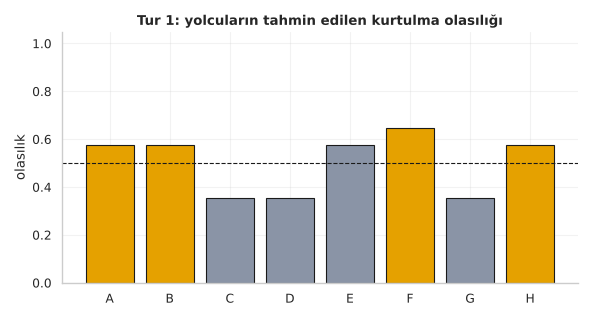

In [9]:
tur_modeli = LGBMClassifier(n_estimators=30, learning_rate=0.3, num_leaves=3, min_child_samples=1, min_data_in_bin=1,
                            verbosity=-1, random_state=RANDOM_STATE).fit(Xo, yo)
olasiliklar = [tur_modeli.predict_proba(Xo, num_iteration=k)[:, 1] for k in range(1, 31)]

def kare(i, fig):
    ax = fig.add_subplot(111)
    renk = [RENK["altin"] if v == 1 else RENK["gri"] for v in yo]
    ax.bar(yolcu["Yolcu"], olasiliklar[i], color=renk, edgecolor="k")
    ax.axhline(0.5, color="k", ls="--", lw=1)
    ax.set(ylim=(0, 1.05), title=f"Tur {i + 1}: yolcuların tahmin edilen kurtulma olasılığı", ylabel="olasılık")
gif_kaydet(kare, 30, "kavram_02_tur_tur_olasilik", figsize=(7.4, 4), fps=5)

<a id="p4"></a>

<p align="center">
  <img src="assets/kavram_04.svg" width="100%" alt="Bölüm 4">
</p>

### 🪣 4.1 · Hile 1: Sayıları Kovalara At

Bilet ücreti (`Fare`) yüzlerce farklı değer alabilir. Klasik ağaç, **her olası kesme noktasını** dener. LightGBM ise önce değerleri **birkaç kovaya** (histogram) ayırır; "ücret kova 5'ten büyük mü?" diye sorar. Aday sayısı **dramatik biçimde** düşer, bilgi büyük ölçüde korunur.

<p align="center">
  <img src="assets/diyagram_histogram.svg" width="100%" alt="Kova hilesi">
</p>

Farklı bilet ücreti sayısı: 248 → olası kesme noktası ≈ 247
8 kovanın sınırları: [  0.    7.8   7.9   9.8  14.5  24.5  31.   69.5 512.3]


🎞️ Animasyon → outputs/figures/kavram_03_kova_animasyonu.gif


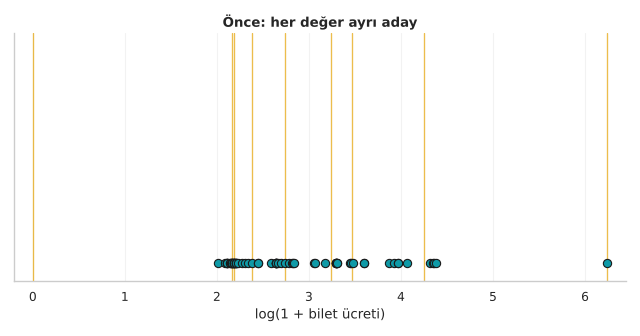

In [10]:
fare = ham["Fare"].to_numpy()
print("Farklı bilet ücreti sayısı:", len(np.unique(fare)), "→ olası kesme noktası ≈", len(np.unique(fare)) - 1)
sinir = np.quantile(fare, np.linspace(0, 1, 9))          # 8 kova (her kovada yaklaşık eşit yolcu)
print("8 kovanın sınırları:", np.round(sinir, 1))

ornek = np.sort(np.random.default_rng(1).choice(fare, 70, replace=False))
kova_no = np.clip(np.searchsorted(sinir, ornek, side="right") - 1, 0, 7)

def kare(i, fig):
    ax = fig.add_subplot(111)
    t = min(1.0, i / 14)                                  # 0 → dağınık, 1 → kovalarda
    sayac = np.zeros(8); ys = []
    for k in kova_no: sayac[k] += 1; ys.append(sayac[k])
    x0 = np.log1p(ornek); xk = np.array([np.log1p((sinir[k] + sinir[k + 1]) / 2) for k in kova_no])
    x = (1 - t) * x0 + t * xk
    y0 = np.full(len(ornek), 0.0); yk = np.array(ys) * 0.6
    ax.scatter(x, (1 - t) * y0 + t * yk, s=55, color=RENK["cyan"], edgecolor="k", zorder=3)
    for s in np.log1p(sinir): ax.axvline(s, color=RENK["altin"], lw=1.2, alpha=0.7)
    ax.set(xlim=(-0.2, np.log1p(fare.max()) + .2), ylim=(-0.8, 10), xlabel="log(1 + bilet ücreti)", yticks=[],
           title="Değerler kovalarına yerleşiyor" if t >= 1 else "Önce: her değer ayrı aday")
gif_kaydet(kare, 20, "kavram_03_kova_animasyonu", figsize=(8, 4.2), fps=5)

### ⏱️ 4.2 · Deney: Kova Sayısı Hız ve Başarıyı Nasıl Etkiler?

LightGBM'de kova sayısı `max_bin` ile ayarlanır (varsayılan 255). Titanik çok küçük olduğundan farkı göstermek için **300 bin satırlık yapay bir veri** kullanıyoruz.

,max_bin,Süre (sn),Test doğruluğu
0,4,1.414,0.933
1,16,1.240,0.972
2,63,1.235,0.973
3,255,1.315,0.973
4,1023,1.632,0.973


📄 Rapor → outputs/reports/kavram_kova_deneyi.csv
💾 Kaydedildi → outputs/figures/kavram_04_kova_deneyi.png


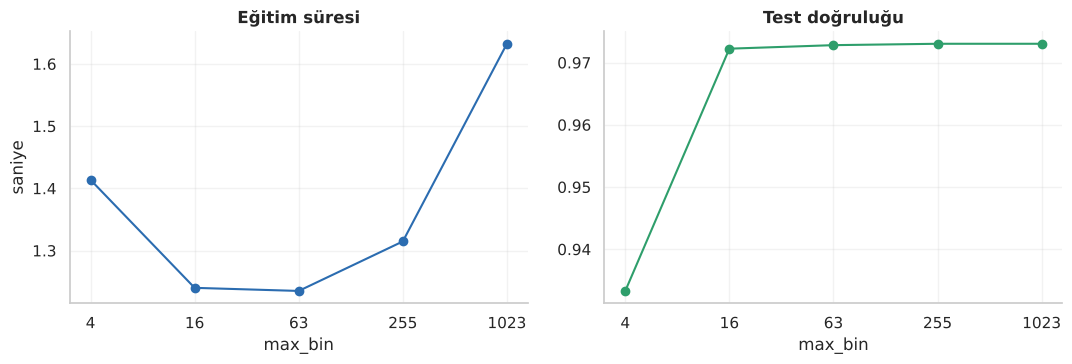

In [11]:
from sklearn.datasets import make_classification
Xb, yb = make_classification(n_samples=300_000, n_features=30, n_informative=12, random_state=RANDOM_STATE)
Xb_e, Xb_t, yb_e, yb_t = train_test_split(Xb, yb, test_size=0.3, random_state=RANDOM_STATE)
satirlar = []
for mb in [4, 16, 63, 255, 1023]:
    t0 = time.perf_counter()
    mdl = LGBMClassifier(n_estimators=100, max_bin=mb, verbosity=-1, random_state=RANDOM_STATE, n_jobs=4).fit(Xb_e, yb_e)
    sure = time.perf_counter() - t0
    satirlar.append({"max_bin": mb, "Süre (sn)": sure, "Test doğruluğu": accuracy_score(yb_t, mdl.predict(Xb_t))})
kova_df = pd.DataFrame(satirlar); display(kova_df.round(3)); rapor_kaydet(kova_df, "kavram_kova_deneyi", index=False)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(kova_df["max_bin"].astype(str), kova_df["Süre (sn)"], "o-", color=RENK["mavi"]); ax[0].set(title="Eğitim süresi", xlabel="max_bin", ylabel="saniye")
ax[1].plot(kova_df["max_bin"].astype(str), kova_df["Test doğruluğu"], "o-", color=RENK["yesil"]); ax[1].set(title="Test doğruluğu", xlabel="max_bin")
plt.tight_layout(); kaydet(fig, "kavram_04_kova_deneyi"); plt.show()

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Çok az kova (4) doğruluğu belirgin düşürür; 16 kovadan sonra doğruluk neredeyse sabittir. Bu ölçekte (300 bin satır, 4 çekirdek) **süre farkı küçük**: kova sayısının asıl getirisi çok daha büyük veride ve bellek kullanımında görünür. Sonuçlar bilgisayarınıza göre değişir.

</td></tr></table>

<a id="p5"></a>

<p align="center">
  <img src="assets/kavram_05.svg" width="100%" alt="Bölüm 5">
</p>

### 🍃 5.1 · Hile 2: Önce En Riskli Güverteye Koş

Bir **arama-kurtarma ekibi** düşünün. Klasik yöntem (XGBoost'un varsayılanı): ekip **her güverteye sırayla** gider, hepsini eşit işler (**katman katman**, *level-wise*). LightGBM ise **şu an en çok iş çıkacak** güverteye koşar (**yaprak yaprak**, *leaf-wise*): her adımda hata azaltımının (kazancın) en büyük olduğu yaprağı böler.

<p align="center">
  <img src="assets/diyagram_yaprak.svg" width="100%" alt="Katman katman ve yaprak yaprak">
</p>

Aşağıdaki animasyon **örnek kazanç değerleriyle** (gerçek veri değil, kavramı göstermek için) aynı sayıda bölünmeyi iki yöntemle yapıyor. Sağ taraftaki ekip **önce büyük kazançları topluyor**.

{'Katman katman (level-wise)': [1, 2, 3, 4, 5, 6, 7], 'Yaprak yaprak (leaf-wise)': [1, 3, 6, 13, 2, 7, 5]}


🎞️ Animasyon → outputs/figures/kavram_05_yaprak_yaprak_buyume.gif


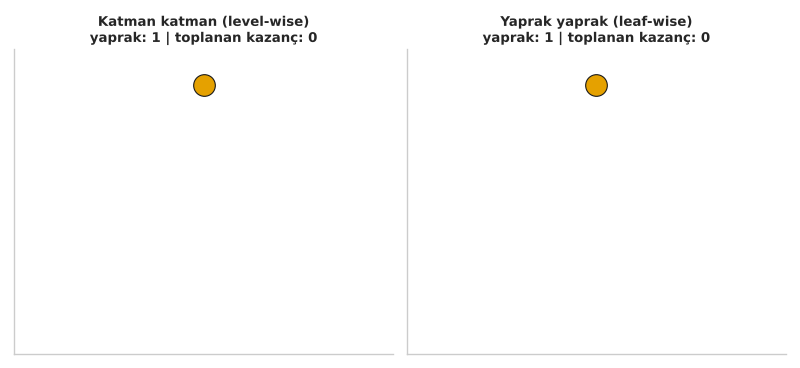

In [12]:
# Yığın (heap) numaralı ikili ağaç: 1 kök, çocuklar 2i ve 2i+1. Değerler: o düğümü bölmenin örnek kazancı.
kazanc_ornek = {1: 100, 2: 30, 3: 60, 4: 12, 5: 15, 6: 45, 7: 20, 12: 10, 13: 38, 14: 8, 15: 9, 26: 5, 27: 4}
def sira_katman(n):
    return [i for i in sorted(kazanc_ornek)][:n]
def sira_yaprak(n):
    yaprak = {1}; secilen = []
    for _ in range(n):
        aday = max((k for k in yaprak if k in kazanc_ornek), key=lambda k: kazanc_ornek[k])
        secilen.append(aday); yaprak.remove(aday); yaprak |= {2 * aday, 2 * aday + 1}
    return secilen
N_BOL = 7
sirala = {"Katman katman (level-wise)": sira_katman(N_BOL), "Yaprak yaprak (leaf-wise)": sira_yaprak(N_BOL)}
print({k: v for k, v in sirala.items()})

def konum(i):
    d = int(np.floor(np.log2(i))); k = i - 2 ** d
    return (k + 0.5) / 2 ** d, -d

def agac_ciz(ax, bolunen, renk, baslik):
    gorunen = {1}
    for s in bolunen: gorunen |= {2 * s, 2 * s + 1}
    for n in gorunen:
        if n > 1:
            x1, y1 = konum(n); x0, y0 = konum(n // 2); ax.plot([x0, x1], [y0, y1], color=RENK["gri"], lw=2, zorder=1)
    for n in gorunen:
        x, y = konum(n); ic = n in bolunen
        ax.scatter(x, y, s=380, color=renk if ic else RENK["altin"], edgecolor="k", zorder=3)
    top = sum(kazanc_ornek[s] for s in bolunen)
    ax.set(xlim=(0, 1), ylim=(-4.4, 0.6), xticks=[], yticks=[], title=f"{baslik}\nyaprak: {len(bolunen) + 1} | toplanan kazanç: {top}")
    ax.grid(False)

def kare(i, fig):
    ax = fig.subplots(1, 2)
    for a, (ad, sr), c in zip(ax, sirala.items(), [RENK["mavi"], RENK["yesil"]]):
        agac_ciz(a, sr[:i], c, ad)
gif_kaydet(kare, N_BOL + 1, "kavram_05_yaprak_yaprak_buyume", figsize=(10, 4.6), fps=1)

### 🔬 5.2 · Deney: Gerçek Ağaçlar Ne Kadar Asimetrik?

Katman katman büyüyen bir ağaçta 8 yaprağın **hepsi derinlik 3'tedir**. LightGBM'de `num_leaves=8` dediğimizde yapraklar farklı derinliklerde olabilir. Titanik'te eğitilmiş 100 ağacın yaprak derinliklerine bakalım.

node_depth,2,3,4,5,6,7,8
Yaprak sayısı,24,149,266,221,99,35,6


💾 Kaydedildi → outputs/figures/kavram_06_yaprak_derinlikleri.png


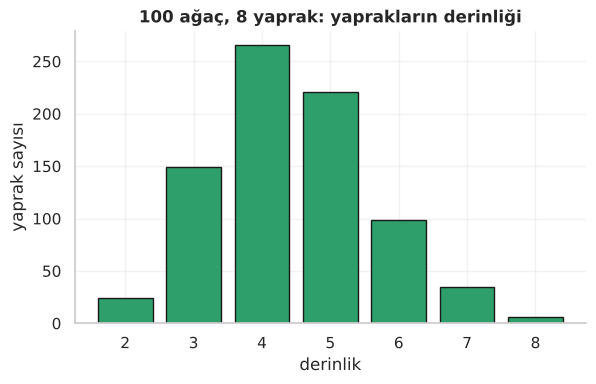

Katman katman büyüseydi: 100 ağacın 800 yaprağı da derinlik 3'te olurdu.


In [13]:
Xt = X.copy()
ag = LGBMClassifier(n_estimators=100, learning_rate=0.05, num_leaves=8, min_child_samples=10, verbosity=-1, random_state=RANDOM_STATE).fit(Xt, y)
td = ag.booster_.trees_to_dataframe()
yaprak_derinlik = td[td["split_feature"].isna()]["node_depth"]
sayim = yaprak_derinlik.value_counts().sort_index()
display(sayim.rename("Yaprak sayısı").to_frame().T)
fig, ax = plt.subplots(figsize=(6.6, 3.8))
ax.bar(sayim.index.astype(str), sayim.values, color=RENK["yesil"], edgecolor="k")
ax.set(title="100 ağaç, 8 yaprak: yaprakların derinliği", xlabel="derinlik", ylabel="yaprak sayısı")
kaydet(fig, "kavram_06_yaprak_derinlikleri"); plt.show()
print("Katman katman büyüseydi: 100 ağacın 800 yaprağı da derinlik 3'te olurdu.")

<table><tr><td>

<img src="assets/etiket_dikkat.svg" height="34" alt="Dikkat">

Yaprak yaprak büyüme **daha düşük hata** verebilir ama ağacı bir tarafa doğru **derinleştirebilir**; küçük veride bu **ezber riskini** artırır. Bu yüzden `num_leaves`, `max_depth` ve `min_child_samples` düğmeleri önemlidir (9. durak).

</td></tr></table>

<a id="p6"></a>

<p align="center">
  <img src="assets/kavram_06.svg" width="100%" alt="Bölüm 6">
</p>

### 🏷️ 6.1 · Etiketler Sayı Olmak Zorunda mı?

Titanik'te `Embarked` (C, Q, S), `Unvan` (Mr, Mrs, Miss…) ve `Guverte` (A, B, C…) gibi **etiket** sütunları var. Çoğu algoritma bunları sayıya çevirmeyi ister. Etiket kodlama **sahte bir sıra** uydurur (Q, C ile S'nin "arasında" mı?); tek-sıcak kodlama ise sütun sayısını şişirir. LightGBM etiketi **olduğu gibi** alıp "bu kümedeki kategoriler bir yana, diğerleri öbür yana" diye bölebilir.

<p align="center">
  <img src="assets/diyagram_kategorik.svg" width="100%" alt="Kategorik sütunlar">
</p>

,Doğruluk,Log-loss
Etiket kodlama (sahte sıra),0.8257,0.4090
Tek-sıcak kodlama,0.8320,0.3989
LightGBM doğal kategori,0.8313,0.4046


📄 Rapor → outputs/reports/kavram_kategorik_deneyi.csv
💾 Kaydedildi → outputs/figures/kavram_07_kategorik_deneyi.png


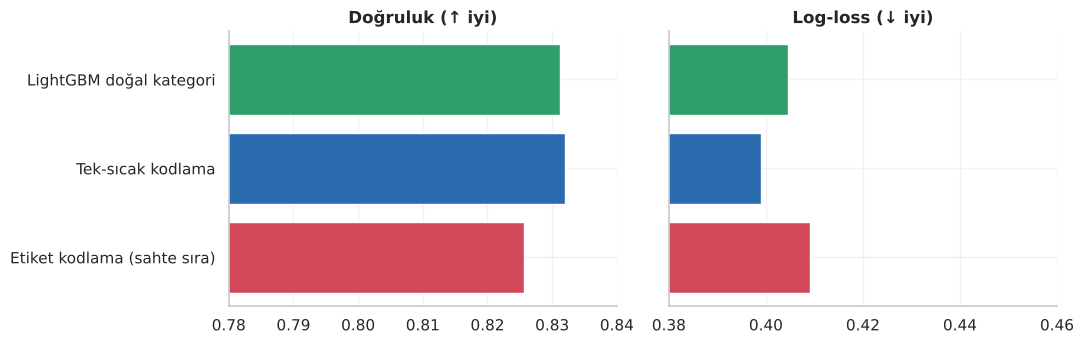

In [14]:
def cv_lgb(Xd, **kw):
    prm = dict(n_estimators=150, learning_rate=0.05, num_leaves=8, min_child_samples=10, verbosity=-1, random_state=RANDOM_STATE)
    prm.update(kw)
    s = cross_val_score(LGBMClassifier(**prm), Xd, y, cv=cv, scoring="neg_log_loss", n_jobs=1)
    a = cross_val_score(LGBMClassifier(**prm), Xd, y, cv=cv, scoring="accuracy", n_jobs=1)
    return a.mean(), -s.mean()

X_kod = X.copy();  X_kod[KATEGORIK] = X_kod[KATEGORIK].apply(lambda c: c.cat.codes).astype(float)   # sahte sıra
X_sicak = pd.get_dummies(X.astype({c: "object" for c in KATEGORIK}), columns=KATEGORIK, dtype=float)   # tek-sıcak
sonuc = {"Etiket kodlama (sahte sıra)": cv_lgb(X_kod), "Tek-sıcak kodlama": cv_lgb(X_sicak), "LightGBM doğal kategori": cv_lgb(X)}
kat_df = pd.DataFrame(sonuc, index=["Doğruluk", "Log-loss"]).T
display(kat_df.round(4)); rapor_kaydet(kat_df, "kavram_kategorik_deneyi")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
renkler = [RENK["pembe"], RENK["mavi"], RENK["yesil"]]
ax[0].barh(kat_df.index, kat_df["Doğruluk"], color=renkler); ax[0].set(xlim=(0.78, 0.84), title="Doğruluk (↑ iyi)")
ax[1].barh(kat_df.index, kat_df["Log-loss"], color=renkler); ax[1].set(xlim=(0.38, 0.46), title="Log-loss (↓ iyi)"); ax[1].set_yticklabels([])
plt.tight_layout(); kaydet(fig, "kavram_07_kategorik_deneyi"); plt.show()

LightGBM'in kategori bölünmesini gerçek ağaçta görelim: eşik sütununda `||` ile ayrılmış kategori numaraları bir **küme** belirtir.

In [15]:
kat_model = LGBMClassifier(n_estimators=30, num_leaves=6, min_child_samples=10, verbosity=-1, random_state=RANDOM_STATE).fit(X, y)
d = kat_model.booster_.trees_to_dataframe()
kategorik_bolunmeler = d[d["split_feature"].isin(["Unvan", "Embarked", "Guverte"])][["tree_index", "split_feature", "threshold", "decision_type"]].head(6)
display(kategorik_bolunmeler)
print("Unvan kategorileri (numara sırasıyla):", list(X["Unvan"].cat.categories))

,tree_index,split_feature,threshold,decision_type
44,4,Unvan,3,==
55,5,Unvan,3,==
96,8,Embarked,3,==
99,9,Unvan,3,==
110,10,Unvan,3,==
121,11,Unvan,3,==


Unvan kategorileri (numara sırasıyla): ['Diger', 'Master', 'Miss', 'Mr', 'Mrs']


<table><tr><td>

<img src="assets/etiket_not.svg" height="34" alt="Not">

Küçük veride doğal kategori her zaman kazandırmaz; nadir kategoriler (ör. tek yolculu güverte `T`) ezbere yol açabilir. LightGBM'de bunu `cat_smooth`, `min_data_per_group` ve `max_cat_threshold` düğmeleriyle yumuşatırız. Sonuç yönünü **ölçerek** karar veriyoruz; burada fark küçük ve kesin hüküm vermiyoruz.

</td></tr></table>

<a id="p7"></a>

<p align="center">
  <img src="assets/kavram_07.svg" width="100%" alt="Bölüm 7">
</p>

### ⚖️ 7.1 · Kazanç: "Bu Soru Ne Kadar İşe Yaradı?"

Ağaç her düğümde onlarca soru arasından birini seçer. Seçim ölçütü **kazançtır**: bölünmeden önceki karışıklık ile bölünmeden sonraki karışıklık arasındaki fark. Daha çok düzen sağlayan soru kazanır.

<p align="center">
  <img src="assets/diyagram_gain.svg" width="100%" alt="Kazanç kavramı">
</p>

İki taraf için "ne kadar yanılıyoruz" ölçüsü olarak **gradyan (G)** ve **eğrilik (H)** toplamları kullanılır; düzenleme katsayısı **λ** aşırı iddialı bölünmeleri frenler:

`Kazanç = G_sol²/(H_sol+λ) + G_sağ²/(H_sağ+λ) − (G_sol+G_sağ)²/(H_sol+H_sağ+λ)`

**Önemli not:** Bu formül XGBoost'ta ve LightGBM'de **aynı** ikinci mertebe mantığına dayanır (Chen ve Guestrin, 2016; Ke vd., 2017). İki kütüphane arasındaki fark formülde değil, **hangi adayları denedikleri**ndedir: XGBoost'un klasik (`exact`) yöntemi her değeri dener; güncel XGBoost'un varsayılanı (`hist`) ise LightGBM gibi kova kullanır. LightGBM kovayı baştan beri tek yöntem olarak kullanır.

### 🔎 7.2 · Doğrulama: Elle Hesap = Kütüphanenin Raporu mu?

891 yolcunun tamamında ilk ağacın kökünü, elle hesapladığımız kazançla LightGBM'in raporladığı `split_gain` ile karşılaştıralım.

In [16]:
p0_t = y.mean()
g_t = p0_t - y; h_t = np.full(len(y), p0_t * (1 - p0_t))
def kazanc_t(maske, lam=0.0):
    GL, HL = g_t[maske].sum(), h_t[maske].sum(); GR, HR = g_t[~maske].sum(), h_t[~maske].sum(); G, H = g_t.sum(), h_t.sum()
    return GL**2 / (HL + lam) + GR**2 / (HR + lam) - G**2 / (H + lam)

Xs = X.copy()
cinsiyet_maske = (Xs["Sex"] == "female").to_numpy()
elle_kazanc = kazanc_t(cinsiyet_maske)
k1 = LGBMClassifier(n_estimators=1, num_leaves=2, learning_rate=0.1, min_child_samples=20, reg_lambda=0.0, verbosity=-1, random_state=RANDOM_STATE).fit(Xs, y)
r = k1.booster_.trees_to_dataframe().iloc[0]
print(f"LightGBM'in kökte seçtiği sütun: {r['split_feature']}  | rapor edilen kazanç: {r['split_gain']:.4f}")
print(f"Elle hesapladığımız «Cinsiyet» kazancı: {elle_kazanc:.4f}")

LightGBM'in kökte seçtiği sütun: Sex  | rapor edilen kazanç: 263.0510
Elle hesapladığımız «Cinsiyet» kazancı: 263.0506


### 🎞️ 7.3 · Aday Yaş Eşiklerini Tarayan Ağaç (Animasyon)

Ağaç `Yaş` sütununda hangi eşikte bölmesi gerektiğini nasıl bulur? Her aday eşik için kazanç hesaplanır; en yüksek olan seçilir. Animasyonda eşik soldan sağa kayıyor, altın yıldız **en iyi eşiği** gösteriyor.

En iyi yaş eşiği: 6  (kazanç 18.634)


🎞️ Animasyon → outputs/figures/kavram_08_kazanc_taramasi.gif


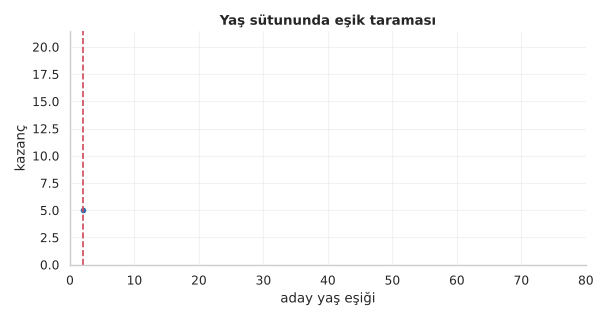

In [17]:
yas = ham["Age"].to_numpy(); bilinen = ~np.isnan(yas)
esikler = np.arange(2, 78, 2)
def yas_kazanc(e):
    m = bilinen & (yas <= e)
    gl, hl = g_t[m].sum(), h_t[m].sum(); gr, hr = g_t[bilinen & ~m].sum(), h_t[bilinen & ~m].sum()
    gt, ht = g_t[bilinen].sum(), h_t[bilinen].sum()
    return gl**2 / hl + gr**2 / hr - gt**2 / ht
kz_yas = np.array([yas_kazanc(e) for e in esikler])
en_i = int(kz_yas.argmax())
print(f"En iyi yaş eşiği: {esikler[en_i]}  (kazanç {kz_yas[en_i]:.3f})")

def kare(i, fig):
    ax = fig.add_subplot(111)
    j = min(i, len(esikler) - 1)
    ax.plot(esikler[: j + 1], kz_yas[: j + 1], "-o", color=RENK["mavi"], ms=4)
    ax.axvline(esikler[j], color=RENK["pembe"], ls="--")
    if j >= len(esikler) - 1 or i >= len(esikler):
        ax.scatter(esikler[en_i], kz_yas[en_i], marker="*", s=420, color=RENK["altin"], edgecolor="k", zorder=5)
        ax.annotate(f"en iyi eşik: {esikler[en_i]} yaş", (esikler[en_i], kz_yas[en_i]), xytext=(12, -4), textcoords="offset points", fontsize=11)
    ax.set(xlim=(0, 80), ylim=(0, kz_yas.max() * 1.15), xlabel="aday yaş eşiği", ylabel="kazanç", title="Yaş sütununda eşik taraması")
gif_kaydet(kare, len(esikler) + 4, "kavram_08_kazanc_taramasi", figsize=(7.6, 4), fps=8)

<a id="p8"></a>

<p align="center">
  <img src="assets/kavram_08.svg" width="100%" alt="Bölüm 8">
</p>

### 🏁 8.1 · İki Kardeş, Aynı Parkur

<p align="center">
  <img src="assets/diyagram_xgb_lgbm.svg" width="100%" alt="XGBoost ve LightGBM">
</p>

Tablodaki "LightGBM daha hızlı" gibi iddiaları **ölçmeden** kabul etmeyelim. İki yarış koşuyoruz: (a) küçük Titanik verisi, (b) 200 bin satırlık yapay veri.

,Doğruluk,Std,Toplam süre (sn)
Model,,,
XGBoost (tek-sıcak),0.8279,0.0211,0.5004
LightGBM (doğal kategori),0.8313,0.0208,0.4332


,Eğitim süresi (sn),Test doğruluğu
Model,,
XGBoost,1.6165,0.9765
LightGBM,1.7121,0.9734


📄 Rapor → outputs/reports/kavram_yaris_titanik.csv
📄 Rapor → outputs/reports/kavram_yaris_buyuk_veri.csv
💾 Kaydedildi → outputs/figures/kavram_09_yaris.png


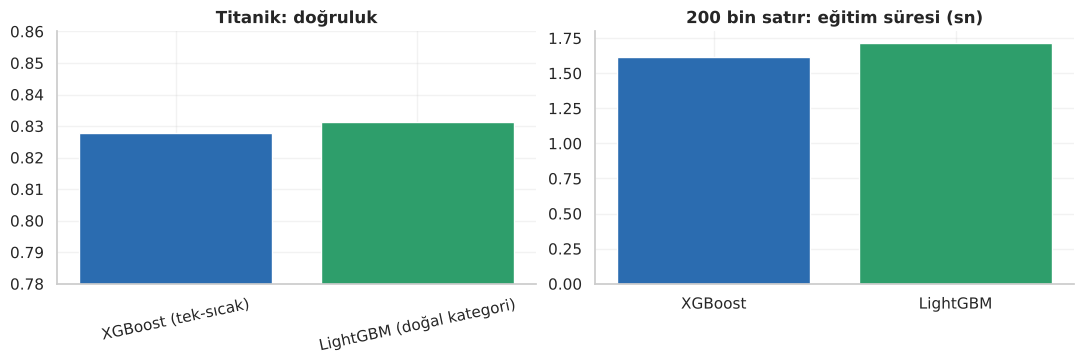

In [18]:
# (a) Titanik: LightGBM kategoriyi doğal, XGBoost tek-sıcak alır; ikisi de eksik değerle çalışır.
xgb_tit = XGBClassifier(n_estimators=150, learning_rate=0.05, max_depth=3, subsample=1.0, tree_method="hist", verbosity=0, random_state=RANDOM_STATE, n_jobs=4)
lgb_tit = LGBMClassifier(n_estimators=150, learning_rate=0.05, num_leaves=8, min_child_samples=10, verbosity=-1, random_state=RANDOM_STATE, n_jobs=4)
satirlar = []
for ad, mdl, Xd in [("XGBoost (tek-sıcak)", xgb_tit, X_sicak), ("LightGBM (doğal kategori)", lgb_tit, X)]:
    t0 = time.perf_counter()
    a = cross_val_score(mdl, Xd, y, cv=cv, scoring="accuracy"); sure = time.perf_counter() - t0
    satirlar.append({"Model": ad, "Doğruluk": a.mean(), "Std": a.std(), "Toplam süre (sn)": sure})
yaris_a = pd.DataFrame(satirlar).set_index("Model"); display(yaris_a.round(4))

# (b) Büyük veri
Xg, yg = make_classification(n_samples=200_000, n_features=40, n_informative=15, random_state=RANDOM_STATE)
Xg_e, Xg_t, yg_e, yg_t = train_test_split(Xg, yg, test_size=0.3, random_state=RANDOM_STATE)
satirlar = []
for ad, mdl in [("XGBoost", XGBClassifier(n_estimators=200, max_depth=6, tree_method="hist", verbosity=0, random_state=RANDOM_STATE, n_jobs=4)),
                ("LightGBM", LGBMClassifier(n_estimators=200, num_leaves=31, verbosity=-1, random_state=RANDOM_STATE, n_jobs=4))]:
    t0 = time.perf_counter(); mdl.fit(Xg_e, yg_e); sure = time.perf_counter() - t0
    satirlar.append({"Model": ad, "Eğitim süresi (sn)": sure, "Test doğruluğu": accuracy_score(yg_t, mdl.predict(Xg_t))})
yaris_b = pd.DataFrame(satirlar).set_index("Model"); display(yaris_b.round(4))
rapor_kaydet(yaris_a, "kavram_yaris_titanik"); rapor_kaydet(yaris_b, "kavram_yaris_buyuk_veri")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].bar(yaris_a.index, yaris_a["Doğruluk"], color=[RENK["mavi"], RENK["yesil"]]); ax[0].set(ylim=(0.78, 0.86), title="Titanik: doğruluk")
ax[0].tick_params(axis="x", labelrotation=12)
ax[1].bar(yaris_b.index, yaris_b["Eğitim süresi (sn)"], color=[RENK["mavi"], RENK["yesil"]]); ax[1].set(title="200 bin satır: eğitim süresi (sn)")
plt.tight_layout(); kaydet(fig, "kavram_09_yaris"); plt.show()

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Her iki yarışta da iki kütüphane **birbirine çok yakın**: Titanik'te doğruluk farkı standart sapmanın çok altında, 200 bin satırda ise süre farkı bu makinede ihmal edilebilir. Yani "LightGBM her zaman daha hızlı" iddiası bu ölçüm koşullarında **doğrulanmadı**; XGBoost'un `hist` yöntemi de aynı kova hilesini kullanır. Hız farkı; veri boyutuna, sütun sayısına, çekirdek sayısına ve parametrelere göre değişir.

</td></tr></table>

<a id="p9"></a>

<p align="center">
  <img src="assets/kavram_09.svg" width="100%" alt="Bölüm 9">
</p>

### 🛡️ 9.1 · Ezberi Önleyen Düğmeler

Yaprak yaprak büyüme güçlüdür ama küçük veride (891 satır) **ezber riski** taşır. Üç temel fren:

| Düğme | Ne yapar? | Gündelik benzetme |
|:--|:--|:--|
| `num_leaves` | Ağaçtaki en fazla yaprak sayısı | Bir çırağın kaç ayrı kural yazabileceği |
| `min_child_samples` | Bir yaprakta en az kaç yolcu olmalı | "Tek kişiye bakarak kural yazma" |
| `learning_rate` (η) | Her çırağın düzeltmesinin boyutu | Küçük adımlar, güvenli yürüyüş |

Her düğmeyi çevirip **eğitim** ve **doğrulama** başarısını yan yana koyalım. Fark açılıyorsa ezber başlıyordur.

💾 Kaydedildi → outputs/figures/kavram_10_frenler.png


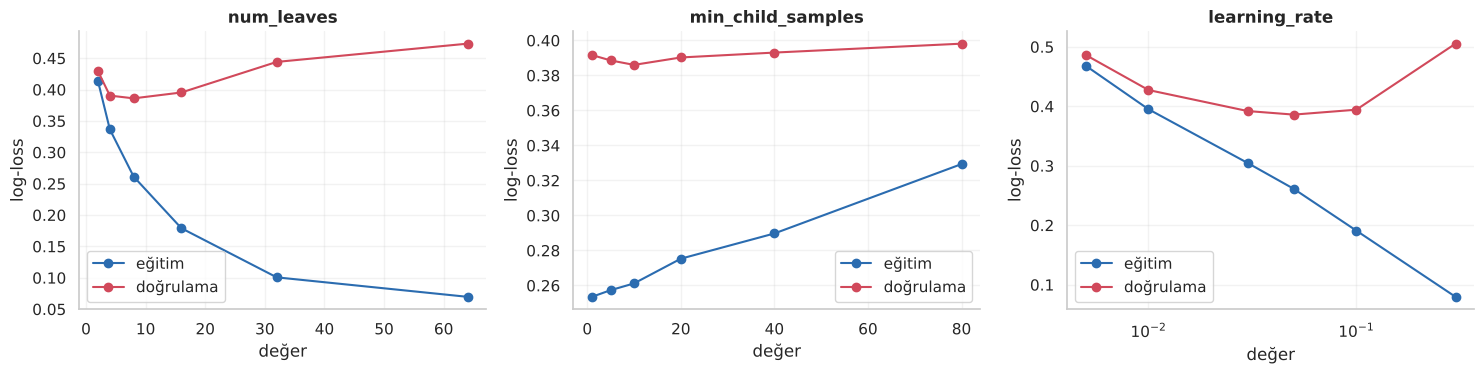

📄 Rapor → outputs/reports/kavram_frenler.csv


,Eğitim log-loss,Doğrulama log-loss
1,0.254,0.392
5,0.257,0.389
10,0.261,0.386
20,0.275,0.390
40,0.290,0.393
80,0.329,0.398


In [19]:
def tr_va(**kw):
    prm = dict(n_estimators=150, learning_rate=0.05, num_leaves=8, min_child_samples=10, verbosity=-1, random_state=RANDOM_STATE); prm.update(kw)
    tr, va = [], []
    for e, t in StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE).split(X, y):
        m = LGBMClassifier(**prm).fit(X.iloc[e], y[e])
        tr.append(log_loss(y[e], m.predict_proba(X.iloc[e])[:, 1])); va.append(log_loss(y[t], m.predict_proba(X.iloc[t])[:, 1]))
    return np.mean(tr), np.mean(va)

fig, eksen = plt.subplots(1, 3, figsize=(15, 3.9))
tum = {}
for ax, (ad, deger) in zip(eksen, {"num_leaves": [2, 4, 8, 16, 32, 64], "min_child_samples": [1, 5, 10, 20, 40, 80], "learning_rate": [0.005, 0.01, 0.03, 0.05, 0.1, 0.3]}.items()):
    sonuc = np.array([tr_va(**{ad: v}) for v in deger]); tum[ad] = pd.DataFrame(sonuc, index=deger, columns=["Eğitim log-loss", "Doğrulama log-loss"])
    ax.plot(deger, sonuc[:, 0], "o-", color=RENK["mavi"], label="eğitim"); ax.plot(deger, sonuc[:, 1], "o-", color=RENK["pembe"], label="doğrulama")
    ax.set(title=ad, xlabel="değer", ylabel="log-loss"); ax.legend()
    if ad == "learning_rate": ax.set_xscale("log")
plt.tight_layout(); kaydet(fig, "kavram_10_frenler"); plt.show()
frenler = pd.concat(tum, names=["düğme", "değer"]); rapor_kaydet(frenler, "kavram_frenler")
display(tum["min_child_samples"].round(3))

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Eğitim ve doğrulama eğrileri **birbirinden uzaklaştığında** model ezberliyordur. Küçük veride en tutucu ayar (az yaprak, büyük `min_child_samples`, küçük η) genellikle en güvenli seçimdir; ama **ölçmeden** karar vermeyin.

</td></tr></table>

### ⏹️ 9.2 · Erken Durdurma: Ne Zaman Dursak?

Çırak eklemeye ne zaman son verelim? Doğrulama hatası artmaya başladığında. `early_stopping` bunu otomatik yapar.

💾 Kaydedildi → outputs/figures/kavram_11_erken_durdurma.png


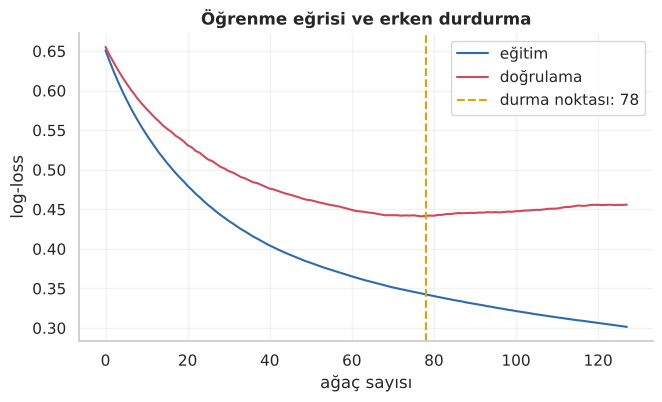

In [20]:
Xe, Xv, ye, yv = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
es = LGBMClassifier(n_estimators=1000, learning_rate=0.03, num_leaves=8, min_child_samples=10, verbosity=-1, random_state=RANDOM_STATE)
es.fit(Xe, ye, eval_set=[(Xe, ye), (Xv, yv)], eval_metric="binary_logloss", callbacks=[lgb.early_stopping(50, verbose=False), lgb.record_evaluation(kayit := {})])
egri = pd.DataFrame({"eğitim": kayit["training"]["binary_logloss"], "doğrulama": kayit["valid_1"]["binary_logloss"]})
fig, ax = plt.subplots(figsize=(7.4, 4))
ax.plot(egri["eğitim"], color=RENK["mavi"], label="eğitim"); ax.plot(egri["doğrulama"], color=RENK["pembe"], label="doğrulama")
ax.axvline(es.best_iteration_, color=RENK["altin"], ls="--", label=f"durma noktası: {es.best_iteration_}")
ax.set(title="Öğrenme eğrisi ve erken durdurma", xlabel="ağaç sayısı", ylabel="log-loss"); ax.legend()
kaydet(fig, "kavram_11_erken_durdurma"); plt.show()

<a id="p10"></a>

<p align="center">
  <img src="assets/kavram_10.svg" width="100%" alt="Bölüm 10">
</p>

### 🎞️ 10.1 · Model Tur Tur Nasıl Şekillenir?

Yalnızca **iki özellik** (yaş ve bilet ücreti) kullanan bir model eğitip her turdan sonra **kurtulma olasılığı haritasını** çizelim. İlk turda harita neredeyse düz; yüzlerce çırak sonra karmaşık bir manzara oluşuyor. (Eksik yaşlar medyanla dolduruldu; yalnızca bu animasyon için.)

🎞️ Animasyon → outputs/figures/kavram_12_tur_tur_harita.gif


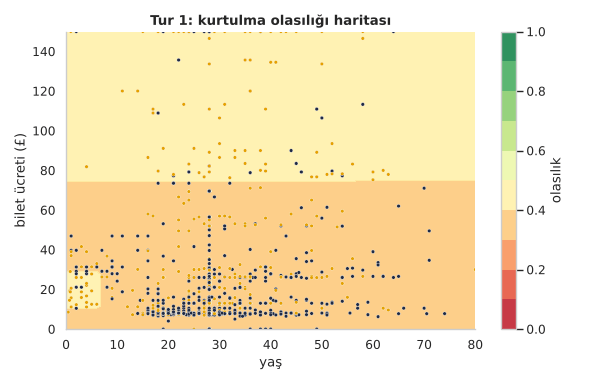

In [21]:
iki = pd.DataFrame({"Yas": ham["Age"].fillna(ham["Age"].median()), "Ucret": ham["Fare"].clip(upper=150)})
harita_modeli = LGBMClassifier(n_estimators=80, learning_rate=0.15, num_leaves=6, min_child_samples=15, verbosity=-1, random_state=RANDOM_STATE).fit(iki, y)
gx, gy = np.meshgrid(np.linspace(0, 80, 120), np.linspace(0, 150, 120))
izgara = pd.DataFrame({"Yas": gx.ravel(), "Ucret": gy.ravel()})
karelen = [1, 2, 3, 5, 8, 12, 18, 25, 35, 50, 65, 80]

def kare(i, fig):
    ax = fig.add_subplot(111); k = karelen[i]
    z = harita_modeli.predict_proba(izgara, num_iteration=k)[:, 1].reshape(gx.shape)
    cs = ax.contourf(gx, gy, z, levels=np.linspace(0, 1, 11), cmap="RdYlGn", alpha=0.85)
    ax.scatter(iki["Yas"], iki["Ucret"], c=np.where(y == 1, RENK["altin"], RENK["koyu"]), s=10, edgecolor="white", linewidth=0.3)
    ax.set(xlabel="yaş", ylabel="bilet ücreti (£)", title=f"Tur {k}: kurtulma olasılığı haritası"); ax.grid(False)
    fig.colorbar(cs, ax=ax, label="olasılık")
gif_kaydet(kare, len(karelen), "kavram_12_tur_tur_harita", figsize=(7.4, 4.8), fps=2)

<a id="p11"></a>

<p align="center">
  <img src="assets/kapanis_kavram.svg" width="100%" alt="Kapanış">
</p>

### 🧠 Akılda Kalacaklar

<table>
<tr><td width="33%" valign="top" align="center"><h3>🔁</h3><b>Hatadan öğrenen ekip</b><br><sub><i>tahmin → artık → yeni ağaç</i></sub><br><br>Her çırak yalnızca <b>kalan hataya</b> bakar; elle hesabımız gerçek kütüphaneyle birebir aynı çıktı<br><br></td><td width="33%" valign="top" align="center"><h3>🪣</h3><b>Kova hilesi</b><br><sub><i>max_bin</i></sub><br><br>Aday kesme noktalarını <b>kova sınırlarına</b> indirir; hız kazandırır, doğruluğu az etkiler<br><br></td><td width="33%" valign="top" align="center"><h3>🍃</h3><b>Yaprak yaprak</b><br><sub><i>leaf-wise</i></sub><br><br>En çok kazandıran yaprağı büyütür; daha hızlı öğrenir ama küçük veride <b>ezber riski</b> taşır<br><br></td></tr>
<tr><td width="33%" valign="top" align="center"><h3>🏷️</h3><b>Doğal kategori</b><br><sub><i>category dtype</i></sub><br><br>Etiketler sayıya çevrilmeden kullanılır; kazanç küçük veride <b>ölçülerek</b> doğrulanmalı<br><br></td><td width="33%" valign="top" align="center"><h3>⚖️</h3><b>Kazanç aynı mantık</b><br><sub><i>G²/(H+λ)</i></sub><br><br>XGBoost ve LightGBM aynı ikinci mertebe kazancı kullanır; fark <b>denenen adaylardadır</b><br><br></td><td width="33%" valign="top" align="center"><h3>🛡️</h3><b>Frenler</b><br><sub><i>num_leaves · min_child_samples · η</i></sub><br><br>Eğitim ve doğrulama eğrileri açılıyorsa model <b>ezberliyordur</b><br><br></td></tr>
</table>

### ❓ Quiz (cevaplar açılır kutularda)

<details><summary><b>1.</b> Boosting'de her yeni ağaç neyi öğrenmeye çalışır?</summary>

Önceki ağaçların bıraktığı **artıkları** (hataları). Her ağaç, ekibin henüz çözemediği kısmı düzeltmeye çalışır.
</details>

<details><summary><b>2.</b> Kova (histogram) hilesi neden hız kazandırır ve ne kaybettirebilir?</summary>

Bir sütundaki yüzlerce değer yerine birkaç **kova sınırı** aday olarak denenir; hesap azalır. Çok az kova seçilirse ince ayrıntılar kaybolur ve doğruluk düşebilir.
</details>

<details><summary><b>3.</b> Yaprak yaprak büyümenin küçük veride riski nedir?</summary>

Ağaç, az sayıdaki yolcuyu ayıran **çok özel kurallar** yazacak kadar derinleşebilir. `num_leaves`, `max_depth` ve `min_child_samples` bunu frenler.
</details>

<details><summary><b>4.</b> LightGBM ile XGBoost'un kazanç formülü farklı mıdır?</summary>

Bu derste elle ve kütüphane raporuyla gösterdiğimiz gibi **hayır**, ikisi de G²/(H+λ) tabanlı ikinci mertebe kazancı kullanır. Fark, hangi aday bölünmelerin denendiğindedir (tüm değerler / kova sınırları).
</details>

<details><summary><b>5.</b> Eğitim hatası düşerken doğrulama hatası yükseliyorsa ne yapmalı?</summary>

Model ezberliyor. Ağaç sayısını azaltın (erken durdurma), `num_leaves`'i küçültün, `min_child_samples`'ı artırın veya öğrenme hızını düşürün.
</details>

### 🏠 Ödevler

1. **Kendi 8 yolcunuzu** tasarlayın (farklı yaş, sınıf ve cinsiyetler) ve 3.3–3.4 hücrelerini yeniden çalıştırın: elle hesap yine kütüphaneyle örtüşüyor mu?
2. 4.2'deki kova deneyini `n_samples=50_000` ile tekrarlayın. Süre farkı hâlâ belirgin mi?
3. 6.1'deki karşılaştırmaya `cat_smooth=50` ve `min_data_per_group=30` ekleyin; doğal kategori sonucu nasıl değişiyor?
4. 9.1'de `num_leaves` ve `min_child_samples` düğmelerini **birlikte** çevirip bir ısı haritası çizin.
5. *(Zor)* Titanik'in `Pclass` sütununu önce sayısal, sonra kategorik verip farkı ölçün.

### 📚 KAYNAKÇA

Metin içi atıflar APA 7 biçimindedir. **Dolaylı atıf**, kaynağa ikinci elden ulaşıldığında "(B, A'dan aktarma)" kalıbıyla gösterilir; bu notebook'taki örnek: *Gradyan artırma fikri (Friedman, 2001, Ke vd., 2017'den aktarma) LightGBM'de kova ve yaprak yaprak büyüme ile hızlandırılmıştır.* Tabular veride ağaç tabanlı modellerin durumu için Grinsztajn vd. (2022) ve güncel kıyaslama olarak Erickson vd. (2025) esas alınmıştır.

- Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 785–794. https://doi.org/10.1145/2939672.2939785
- Erickson, N., Purucker, L., Tschalzev, A., Holzmüller, D., Desai, P. M., Salinas, D., & Hutter, F. (2025). *TabArena: A living benchmark for machine learning on tabular data*. arXiv. https://arxiv.org/abs/2506.16791
- Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189–1232. https://doi.org/10.1214/aos/1013203451
- Grinsztajn, L., Oyallon, E., & Varoquaux, G. (2022). Why do tree-based models still outperform deep learning on typical tabular data? *Advances in Neural Information Processing Systems, 35* (Datasets and Benchmarks Track). https://arxiv.org/abs/2207.08815
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*, 3146–3154.
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., … Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
- Prokhorenkova, L., Gusev, G., Vorobev, A., Dorogush, A. V., & Gulin, A. (2018). CatBoost: Unbiased boosting with categorical features. *Advances in Neural Information Processing Systems, 31*, 6638–6648.